## Buyer and Seller Representation

In [1]:
class Buyer:
    """Represents a buyer willing to buy at a specific price"""
    def __init__(self, price, quantity):
        self.bid_price = price      # Price buyer is willing to pay
        self.quantity = quantity     # How much they want to buy
    
    def __repr__(self):
        return f"Buyer(bid=${self.bid_price}, qty={self.quantity})"

In [2]:
class Seller:
    """Represents a seller willing to sell at a specific price"""
    def __init__(self, price, quantity):
        self.ask_price = price      # Price seller wants to receive
        self.quantity = quantity     # How much they want to sell
    
    def __repr__(self):
        return f"Seller(ask=${self.ask_price}, qty={self.quantity})"

## Match a buyer and seller order.

- Buyer wants to buy at price buyer_bid_price.
- Seller wants to sell at price seller_ask_price.
    
**RULE:**
Trade happens when:
buyer_bid_price >= seller_ask_price
    
**Logic:**
- If buyer willing to pay $100 and seller wants $98 → they agree!
- If buyer willing to pay $95 and seller wants $105 → they disagree

**Price** = where they meet (transaction price)

In [3]:
def match_order(buyer: Buyer, seller: Seller) -> dict:   
    # Check if orders can match
    if buyer.bid_price >= seller.ask_price:
        # YES - they can trade!
        
        # Transaction price = average of bid and ask
        # (In real markets, it's usually the maker's price, but we'll use midpoint for now)
        transaction_price = (buyer.bid_price + seller.ask_price) / 2
        
        # Quantity filled = minimum of what both want
        # (If buyer wants 10 but seller has 5, only 5 trade)
        quantity_filled = min(buyer.quantity, seller.quantity)
        
        return {
            'matched': True,
            'transaction_price': transaction_price,
            'quantity_filled': quantity_filled,
            'buyer_bid': buyer.bid_price,
            'seller_ask': seller.ask_price,
        }
    else:
        # NO - there's a gap between them
        return {
            'matched': False,
            'transaction_price': None,
            'quantity_filled': None,
            'buyer_bid': buyer.bid_price,
            'seller_ask': seller.ask_price,
            'spread': seller.ask_price - buyer.bid_price,  # The gap
        }

### SCENARIO 1: Orders match (buyer bid >= seller ask)

In [4]:
buyer1 = Buyer(price=100, quantity=10)
seller1 = Seller(price=98, quantity=5)

print(f"Buyer:  {buyer1}")
print(f"Seller: {seller1}")
print(f"\nAnalysis:")
print(f"  Buyer willing to pay: ${buyer1.bid_price}")
print(f"  Seller willing to accept: ${seller1.ask_price}")
print(f"  Comparison: ${buyer1.bid_price} >= ${seller1.ask_price}?")
print(f"  Answer: {buyer1.bid_price >= seller1.ask_price}, MATCH!")

result1 = match_order(buyer1, seller1)
print(f"\n Trade executed:")
print(f"   Transaction price: ${result1['transaction_price']}")
print(f"   Quantity filled: {result1['quantity_filled']} units")
# All 5 units from seller are sold, buyer still wants 5 more (partially filled)

Buyer:  Buyer(bid=$100, qty=10)
Seller: Seller(ask=$98, qty=5)

Analysis:
  Buyer willing to pay: $100
  Seller willing to accept: $98
  Comparison: $100 >= $98?
  Answer: True, MATCH!

 Trade executed:
   Transaction price: $99.0
   Quantity filled: 5 units


### SCENARIO 2: Orders don't match (buyer bid < seller ask)

In [5]:
# Gap in the market
buyer2 = Buyer(price=95, quantity=10)
seller2 = Seller(price=105, quantity=5)

print(f"Buyer:  {buyer2}")
print(f"Seller: {seller2}")
print(f"\nAnalysis:")
print(f"  Buyer willing to pay: ${buyer2.bid_price}")
print(f"  Seller willing to accept: ${seller2.ask_price}")
print(f"  Comparison: ${buyer2.bid_price} >= ${seller2.ask_price}?")
print(f"  Answer: {buyer2.bid_price >= seller2.ask_price}, NO MATCH")

result2 = match_order(buyer2, seller2)
print(f"\n No trade:")
print(f"   Spread (gap): ${result2['spread']}")
# These orders sit in the 'order book' waiting for better prices

Buyer:  Buyer(bid=$95, qty=10)
Seller: Seller(ask=$105, qty=5)

Analysis:
  Buyer willing to pay: $95
  Seller willing to accept: $105
  Comparison: $95 >= $105?
  Answer: False, NO MATCH

 No trade:
   Spread (gap): $10


### SCENARIO 3: Exact match at same price

In [6]:
buyer3 = Buyer(price=100, quantity=7)
seller3 = Seller(price=100, quantity=12)

print(f"Buyer:  {buyer3}")
print(f"Seller: {seller3}")
print(f"\nAnalysis:")
print(f"  Buyer willing to pay: ${buyer3.bid_price}")
print(f"  Seller willing to accept: ${seller3.ask_price}")
print(f"  Comparison: ${buyer3.bid_price} >= ${seller3.ask_price}?")
print(f"  Answer: {buyer3.bid_price >= seller3.ask_price}, MATCH!")

result3 = match_order(buyer3, seller3)
print(f"\n Trade executed:")
print(f"   Transaction price: ${result3['transaction_price']}")
print(f"   Quantity filled: {result3['quantity_filled']} units")
# All 7 units from buyer are filled, seller still has 5 left (partially filled)

Buyer:  Buyer(bid=$100, qty=7)
Seller: Seller(ask=$100, qty=12)

Analysis:
  Buyer willing to pay: $100
  Seller willing to accept: $100
  Comparison: $100 >= $100?
  Answer: True, MATCH!

 Trade executed:
   Transaction price: $100.0
   Quantity filled: 7 units


## Representation for Single Buy or Sell Order

In [7]:
import numpy as np
import pandas as pd
from collections import defaultdict

class Order:
    order_id_counter = 0

    def __init__(self, side, price, quantity, timestamp=0, order_type="LIMIT"):
        self.order_id = Order.order_id_counter
        Order.order_id_counter += 1

        self.side = side                  # 'BUY' or 'SELL'
        self.price = price                # float for LIMIT, None for MARKET
        self.quantity = quantity
        self.filled_quantity = 0
        self.timestamp = timestamp
        self.order_type = order_type      # 'LIMIT' or 'MARKET'

    def is_filled(self):
        return self.filled_quantity >= self.quantity

    def remaining_quantity(self):
        return self.quantity - self.filled_quantity

    def __repr__(self):
        if self.order_type == "MARKET":
            return f"Order({self.order_id}, {self.side}, MARKET, qty={self.quantity})"
        return f"Order({self.order_id}, {self.side}, ${self.price:.2f}, qty={self.quantity})"

## Demonstration of Order Book 
(Where track of all open orders is kept)

- BUY orders (bids) sorted from highest to lowest price
- SELL orders (asks) sorted from lowest to highest price

In addition,
- Orders do not live forever. They get canceled (or expire) randomly.
- This prevents the book from “freezing” into huge walls and makes price move more realistically.

In [8]:
class OrderBook:
    
    def __init__(self):
        # Store orders: key = price level, value = list of orders at that price
        self.bids = defaultdict(list)  # BUY orders
        self.asks = defaultdict(list)  # SELL orders
        self.all_orders = {}           # All orders indexed by ID
        self.trades = []               # Record of all trades
    
    def add_order(self, order: Order):
        # Add a new order to the book
        self.all_orders[order.order_id] = order
        
        if order.side == 'BUY':
            self.bids[order.price].append(order)
        else:  # SELL
            self.asks[order.price].append(order)
    
    def get_best_bid(self) -> float:
        # Get the highest buy price
        return max(self.bids.keys()) if self.bids else None
    
    def get_best_ask(self) -> float:
        # Get the lowest sell price
        return min(self.asks.keys()) if self.asks else None
    
    def get_spread(self) -> float:
        # Get the current bid-ask spread
        bid = self.get_best_bid()
        ask = self.get_best_ask()
        if bid is None or ask is None:
            return None
        return ask - bid
    
    def get_mid_price(self) -> float:
        # Get the mid price between best bid and ask
        bid = self.get_best_bid()
        ask = self.get_best_ask()
        if bid is None or ask is None:
            return None
        return (bid + ask) / 2
    
    def remove_order(self, order_id: int):
        # Remove an order (cancellation)
        if order_id not in self.all_orders:
            return
        
        order = self.all_orders[order_id]
        
        if order.side == 'BUY':
            if order.price in self.bids:
                self.bids[order.price] = [o for o in self.bids[order.price] if o.order_id != order_id]
                if not self.bids[order.price]:
                    del self.bids[order.price]
        else:  # SELL
            if order.price in self.asks:
                self.asks[order.price] = [o for o in self.asks[order.price] if o.order_id != order_id]
                if not self.asks[order.price]:
                    del self.asks[order.price]
        
        del self.all_orders[order_id]
    
    def __repr__(self):
        bid = self.get_best_bid()
        ask = self.get_best_ask()
        spread = self.get_spread()
        return (f"OrderBook(bid=${bid}, ask=${ask}, spread=${spread}, "f"total_orders={len(self.all_orders)})")
    
    def get_all_order_ids(self):
        # Return a list of all current order IDs in the book
        return list(self.all_orders.keys())

    def cancel_random_order(self, rng: np.random.Generator):
        # Randomly select an order ID and remove it from the book
        ids = self.get_all_order_ids()
        if not ids:
            return None
        order_id = int(rng.choice(ids))
        order = self.all_orders[order_id]
        self.remove_order(order_id)
        return order

    def depth_snapshot(self, levels=5):
        # Return a small snapshot of top-of-book depth for debugging/learning.
        # levels: number of price levels to show on each side.
        
        bid_prices = sorted(self.bids.keys(), reverse=True)[:levels]
        ask_prices = sorted(self.asks.keys())[:levels]

        bids_view = [(p, sum(o.remaining_quantity() for o in self.bids[p])) for p in bid_prices]
        asks_view = [(p, sum(o.remaining_quantity() for o in self.asks[p])) for p in ask_prices]
        return {"bids": bids_view, "asks": asks_view}
    
# prevent invalid orders from entering the book

_original_add_order = OrderBook.add_order

def _patched_add_order(self, order: Order):
    if order.side not in ("BUY", "SELL"):
        raise ValueError(f"Invalid side: {order.side}")

    if order.order_type != "LIMIT":
        raise ValueError("Only LIMIT orders can be added to the book")

    if order.price is None:
        raise ValueError("LIMIT order must have a price (got None)")

    if order.quantity is None or order.quantity <= 0:
        raise ValueError(f"Order quantity must be > 0 (got {order.quantity})")

    return _original_add_order(self, order)

OrderBook.add_order = _patched_add_order    

## The Core Logic
**Matching Engine:**
Matches incoming orders against the order book.

**Rule:**
- When a BUY order arrives → match against SELL orders (ASKs)
    (from lowest price upward)
- When a SELL order arrives → match against BUY orders (BIDs)
    (from highest price downward)

In [9]:
class MatchingEngine:
    def __init__(self, book: OrderBook):
        self.book = book

    def match_order(self, incoming_order: Order) -> list:
        """
        Supports:
          - LIMIT orders (price is float)
          - MARKET orders (price is None)
        """
        if incoming_order.side == "BUY":
            trades = self._match_buy(incoming_order)
        else:
            trades = self._match_sell(incoming_order)

        # Only LIMIT orders can rest in the book
        if incoming_order.order_type == "LIMIT" and not incoming_order.is_filled():
            self.book.add_order(incoming_order)

        return trades

    def _match_buy(self, buy_order: Order) -> list:
        trades = []
        ask_prices = sorted(self.book.asks.keys())  # low to high

        for ask_price in ask_prices:
            # For LIMIT BUY: stop if price can't cross
            if buy_order.order_type == "LIMIT" and buy_order.price < ask_price:
                break

            sellers = self.book.asks[ask_price].copy()
            for sell_order in sellers:
                if buy_order.is_filled():
                    break

                qty = min(buy_order.remaining_quantity(), sell_order.remaining_quantity())

                trades.append({
                    "timestamp": buy_order.timestamp,
                    "price": ask_price,
                    "quantity": qty,
                    "taker_side": "BUY" if buy_order.order_type == "MARKET" else "BUY_LIMIT_CROSS",
                    "buy_order_id": buy_order.order_id,
                    "sell_order_id": sell_order.order_id,
                })

                buy_order.filled_quantity += qty
                sell_order.filled_quantity += qty

                if sell_order.is_filled():
                    self.book.asks[ask_price].remove(sell_order)

            if ask_price in self.book.asks and not self.book.asks[ask_price]:
                del self.book.asks[ask_price]

            if buy_order.is_filled():
                break

        return trades

    def _match_sell(self, sell_order: Order) -> list:
        trades = []
        bid_prices = sorted(self.book.bids.keys(), reverse=True)  # high to low

        for bid_price in bid_prices:
            # For LIMIT SELL: stop if price can't cross
            if sell_order.order_type == "LIMIT" and sell_order.price > bid_price:
                break

            buyers = self.book.bids[bid_price].copy()
            for buy_order in buyers:
                if sell_order.is_filled():
                    break

                qty = min(sell_order.remaining_quantity(), buy_order.remaining_quantity())

                trades.append({
                    "timestamp": sell_order.timestamp,
                    "price": bid_price,
                    "quantity": qty,
                    "taker_side": "SELL" if sell_order.order_type == "MARKET" else "SELL_LIMIT_CROSS",
                    "buy_order_id": buy_order.order_id,
                    "sell_order_id": sell_order.order_id,
                })

                sell_order.filled_quantity += qty
                buy_order.filled_quantity += qty

                if buy_order.is_filled():
                    self.book.bids[bid_price].remove(buy_order)

            if bid_price in self.book.bids and not self.book.bids[bid_price]:
                del self.book.bids[bid_price]

            if sell_order.is_filled():
                break

        return trades

## Generating Random Orders and Simulating the Market

In [10]:
class MarketSimulator0:
    
    def __init__(self, num_orders=50, initial_price=100, seed=42):
        self.num_orders = num_orders
        self.initial_price = initial_price
        self.rng = np.random.default_rng(seed)
        
        self.book = OrderBook()
        self.engine = MatchingEngine(self.book)
        self.all_trades = []
    
    def generate_random_order(self, timestamp: int) -> Order:
        """
        Generate a random order with mathematical properties:
        - Side: 50/50 BUY or SELL
        - Price: Normal distribution around current price
        - Quantity: Exponential distribution (small orders more common)
        """
        
        # Current mid price
        mid = self.book.get_mid_price()
        if mid is None:
            mid = self.initial_price
        
        # Random side
        side = 'BUY' if self.rng.random() < 0.5 else 'SELL'
        
        # Price: Normal distribution around current price (±5% typically)
        price_offset = self.rng.normal(0, mid * 0.02)  # 2% std dev
        price = mid + price_offset
        price = max(1, price)  # Ensure positive price
        
        # Quantity: Exponential (small orders common, large orders rare)
        quantity = int(max(1, self.rng.exponential(scale=5)))
        
        return Order(side=side, price=price, quantity=quantity, timestamp=timestamp)
    
    def run(self):
        print(f"Simulating {self.num_orders} random orders...\n")
        
        for t in range(self.num_orders):
            # Generate random order
            order = self.generate_random_order(t)
            
            # Match it
            trades = self.engine.match_order(order)
            self.all_trades.extend(trades)
            
            # Print status
            if (t + 1) % 10 == 0 or t == 0:
                bid = self.book.get_best_bid()
                ask = self.book.get_best_ask()
                mid = self.book.get_mid_price()
                spread = self.book.get_spread()
                
                # Safe formatting
                fmt = lambda v: f"${v:.2f}" if v is not None else "N/A"
                print(f"[{t+1:3d}] Order: {order}")
                print(f"       Book: bid={fmt(bid)} | mid={fmt(mid)} | ask={fmt(ask)} | spread={fmt(spread)} | trades={len(self.all_trades)}")
                print()
        return self.all_trades
    
    def get_trade_prices(self) -> list:
        # Extract trade prices from all trades
        return [trade['price'] for trade in self.all_trades]
    
    def get_statistics(self) -> dict:
        # Compute statistics on trade prices
        prices = self.get_trade_prices()
        
        if not prices:
            return None
        
        return {
            'num_trades': len(self.all_trades),
            'first_price': prices[0],
            'last_price': prices[-1],
            'min_price': min(prices),
            'max_price': max(prices),
            'avg_price': np.mean(prices),
            'std_price': np.std(prices),
            'price_range': max(prices) - min(prices),
        }

## Generating Random Orders and cancellations; Simulating the Market

In [11]:
class MarketSimulator1:
    """
    - Random limit order arrivals
    - Random cancellations of resting orders
    - Matching via order book
    """

    def __init__(self,num_events=500,initial_price=100.0,seed=42,
        p_cancel=0.30,          # probability an event is a cancellation
        price_sigma_pct=0.02,   # std dev of limit prices around mid, as % of mid
        qty_scale=5.0,          # exponential scale for sizes
        print_every=50
    ):
        self.num_events = num_events
        self.initial_price = initial_price
        self.rng = np.random.default_rng(seed)

        self.p_cancel = p_cancel
        self.price_sigma_pct = price_sigma_pct
        self.qty_scale = qty_scale
        self.print_every = print_every

        self.book = OrderBook()
        self.engine = MatchingEngine(self.book)

        self.all_trades = []
        self.event_log = []  # record cancellations and order arrivals

    def _current_mid(self):
        mid = self.book.get_mid_price()
        return mid if mid is not None else self.initial_price

    def generate_random_limit_order(self, timestamp: int) -> Order:
        mid = self._current_mid()

        side = 'BUY' if self.rng.random() < 0.5 else 'SELL'

        sigma = mid * self.price_sigma_pct
        price = mid + self.rng.normal(0.0, sigma)
        price = max(1e-6, price)

        quantity = int(max(1, self.rng.exponential(scale=self.qty_scale)))

        return Order(side=side, price=price, quantity=quantity, timestamp=timestamp)

    def run(self):
        print(f"Events: {self.num_events} | p_cancel={self.p_cancel}\n")

        fmt = lambda v: f"${v:.2f}" if v is not None else "N/A"

        for t in range(self.num_events):
            # Decide event type
            if self.rng.random() < self.p_cancel:
                # Cancellation event
                canceled = self.book.cancel_random_order(self.rng)
                self.event_log.append({
                    "timestamp": t,
                    "event": "CANCEL",
                    "order_id": None if canceled is None else canceled.order_id,
                    "side": None if canceled is None else canceled.side,
                    "price": None if canceled is None else canceled.price,
                    "quantity": None if canceled is None else canceled.remaining_quantity(),
                })
            else:
                # New limit order event
                order = self.generate_random_limit_order(t)
                trades = self.engine.match_order(order)
                self.all_trades.extend(trades)

                self.event_log.append({
                    "timestamp": t,
                    "event": "NEW_ORDER",
                    "order_id": order.order_id,
                    "side": order.side,
                    "price": order.price,
                    "quantity": order.quantity,
                    "trades_generated": len(trades),
                })

            # Status printing
            if t == 0 or (t + 1) % self.print_every == 0:
                bid = self.book.get_best_bid()
                ask = self.book.get_best_ask()
                mid = self.book.get_mid_price()
                spread = self.book.get_spread()

                print(f"[{t+1:4d}] book: bid={fmt(bid)} | mid={fmt(mid)} | ask={fmt(ask)} | spread={fmt(spread)} "
                      f"| resting_orders={len(self.book.all_orders)} | trades={len(self.all_trades)}")

        return self.all_trades

    def trades_df(self):
        return pd.DataFrame(self.all_trades) if self.all_trades else pd.DataFrame()

    def events_df(self):
        return pd.DataFrame(self.event_log)

    def trade_price_series(self):
        return [tr["price"] for tr in self.all_trades]

    def stats(self):
        prices = self.trade_price_series()
        if not prices:
            return None
        prices = np.array(prices, dtype=float)
        returns = np.diff(np.log(prices)) if len(prices) > 1 else np.array([])

        return {
            "num_trades": len(prices),
            "first": float(prices[0]),
            "last": float(prices[-1]),
            "min": float(prices.min()),
            "max": float(prices.max()),
            "mean": float(prices.mean()),
            "std": float(prices.std()),
            "log_return_std": float(returns.std()) if len(returns) else None,
        }

## Generating Random Orders and cancellations; Simulating the Market

in addition to: limit orders, market orders, record and OHLCV candles.

In [12]:
import numpy as np
import pandas as pd

class MarketSimulator2:
    def __init__(self,num_events=5000,initial_price=100.0,seed=42,p_cancel=0.20,
        p_market=0.25,        # of NON-cancel events, fraction that are MARKET orders
        p_buy=0.50,           # probability side is BUY
        price_sigma_pct=0.01, # limit price dispersion around mid
        qty_scale=5.0,
        candle_size_events=50,  # build candles by event-count (simple & robust)
        print_every=500
    ):
        self.num_events = num_events
        self.initial_price = initial_price
        self.rng = np.random.default_rng(seed)

        self.p_cancel = p_cancel
        self.p_market = p_market
        self.p_buy = p_buy
        self.price_sigma_pct = price_sigma_pct
        self.qty_scale = qty_scale

        self.candle_size_events = candle_size_events
        self.print_every = print_every

        self.book = OrderBook()
        self.engine = MatchingEngine(self.book)

        self.trades = []
        self.events = []

    def _mid_or_initial(self):
        mid = self.book.get_mid_price()
        return mid if mid is not None else self.initial_price

    def _random_side(self):
        return "BUY" if self.rng.random() < self.p_buy else "SELL"

    def _random_qty(self):
        return int(max(1, self.rng.exponential(scale=self.qty_scale)))

    def _make_limit_order(self, t):
        mid = self._mid_or_initial()
        sigma = mid * self.price_sigma_pct
        price = max(1e-6, mid + self.rng.normal(0.0, sigma))
        return Order(side=self._random_side(), price=price, quantity=self._random_qty(),
                     timestamp=t, order_type="LIMIT")

    def _make_market_order(self, t):
        return Order(side=self._random_side(), price=None, quantity=self._random_qty(),
                     timestamp=t, order_type="MARKET")

    def run(self):
        fmt = lambda v: f"{v:.2f}" if v is not None else "N/A"

        empty_market_orders = 0
        total_market_orders = 0

        for t in range(self.num_events):
            if self.rng.random() < self.p_cancel:
                canceled = self.book.cancel_random_order(self.rng)
                self.events.append({
                    "timestamp": t,
                    "event": "CANCEL",
                    "order_id": None if canceled is None else canceled.order_id
                })
            else:
                is_market = self.rng.random() < self.p_market
                order = self._make_market_order(t) if is_market else self._make_limit_order(t)

                if is_market:
                    total_market_orders += 1
                    if order.side == "BUY" and len(self.book.asks) == 0:
                        empty_market_orders += 1
                    elif order.side == "SELL" and len(self.book.bids) == 0:
                        empty_market_orders += 1

                new_trades = self.engine.match_order(order)
                self.trades.extend(new_trades)

                self.events.append({
                    "timestamp": t,
                    "event": "MARKET" if is_market else "LIMIT",
                    "side": order.side,
                    "qty": order.quantity,
                    "trades_generated": len(new_trades)
                })

            if t == 0 or (t + 1) % self.print_every == 0:
                bid = self.book.get_best_bid()
                ask = self.book.get_best_ask()
                mid = self.book.get_mid_price()
                spread = self.book.get_spread()

                print(f"[{t+1:5d}] bid={fmt(bid)} ask={fmt(ask)} mid={fmt(mid)} spread={fmt(spread)} "
                      f"| resting={len(self.book.all_orders)} trades={len(self.trades)} "
                      f"| market={total_market_orders} empty_market={empty_market_orders}")

        print("\n Market order check")
        print("Total market orders:", total_market_orders)
        print("Market orders with empty opposite book:", empty_market_orders)
        if total_market_orders > 0:
            print("Fraction empty:", empty_market_orders / total_market_orders)

        return self.trades

    def trades_df(self):
        return pd.DataFrame(self.trades) if self.trades else pd.DataFrame()
    
    def trade_price_series(self):
        return [t["price"] for t in self.trades if "price" in t]

    def make_ohlcv(self):
        # Build OHLCV candles using event-time buckets.
        # We assign each trade to a candle by: candle_id = timestamp // candle_size_events
        if not self.trades:
            return pd.DataFrame()

        df = pd.DataFrame(self.trades).copy()
        df["candle"] = (df["timestamp"] // self.candle_size_events).astype(int)

        ohlc = df.groupby("candle")["price"].agg(open="first", high="max", low="min", close="last")
        vol = df.groupby("candle")["quantity"].sum().rename("volume")

        out = pd.concat([ohlc, vol], axis=1).reset_index()
        return out

## Running the Simulation 0

In [13]:
sim = MarketSimulator0(num_orders=50, initial_price=100, seed=42)
trades = sim.run()

# Print statistics
stats = sim.get_statistics()
print("\n MARKET STATISTICS:")
print(f"  Total trades: {stats['num_trades']}")
print(f"  First trade price: ${stats['first_price']:.2f}")
print(f"  Last trade price: ${stats['last_price']:.2f}")
print(f"  Price range: ${stats['min_price']:.2f} - ${stats['max_price']:.2f}")
print(f"  Average price: ${stats['avg_price']:.2f}")
print(f"  Price std dev: ${stats['std_price']:.2f}")
print(f"  Total movement: ${stats['price_range']:.2f}")

# Print all trades as table
print("\n ALL TRADES:")
trades_df = pd.DataFrame(trades)
print(trades_df.to_string(index=False))

Simulating 50 random orders...

[  1] Order: Order(0, SELL, $97.92, qty=11)
       Book: bid=N/A | mid=N/A | ask=$97.92 | spread=N/A | trades=0

[ 10] Order: Order(9, BUY, $100.83, qty=3)
       Book: bid=N/A | mid=N/A | ask=$97.92 | spread=N/A | trades=5

[ 20] Order: Order(19, SELL, $98.26, qty=1)
       Book: bid=$98.32 | mid=$98.81 | ask=$99.30 | spread=$0.98 | trades=11

[ 30] Order: Order(29, BUY, $98.22, qty=4)
       Book: bid=$99.01 | mid=$99.15 | ask=$99.30 | spread=$0.29 | trades=14

[ 40] Order: Order(39, SELL, $99.92, qty=1)
       Book: bid=$99.01 | mid=$99.45 | ask=$99.90 | spread=$0.89 | trades=22

[ 50] Order: Order(49, SELL, $98.75, qty=1)
       Book: bid=$98.35 | mid=$99.17 | ask=$99.99 | spread=$1.63 | trades=31


 MARKET STATISTICS:
  Total trades: 31
  First trade price: $96.10
  Last trade price: $99.96
  Price range: $96.10 - $99.99
  Average price: $98.85
  Price std dev: $1.09
  Total movement: $3.89

 ALL TRADES:
 timestamp     price  quantity       taker_si

## Running the Simulation 1

In [14]:
sim1 = MarketSimulator1(num_events=1000,initial_price=100,seed=42,p_cancel=0.35,price_sigma_pct=0.02,qty_scale=5.0,print_every=100)

trades1 = sim1.run()

stats = sim1.stats()
print("\nSTATS:", stats)

df_trades1 = sim1.trades_df()
display(df_trades1.head())

prices = sim1.trade_price_series()

Events: 1000 | p_cancel=0.35

[   1] book: bid=$101.50 | mid=N/A | ask=N/A | spread=N/A | resting_orders=1 | trades=0
[ 100] book: bid=$102.33 | mid=$102.82 | ask=$103.30 | spread=$0.98 | resting_orders=18 | trades=22
[ 200] book: bid=$100.47 | mid=$100.58 | ask=$100.69 | spread=$0.22 | resting_orders=26 | trades=55
[ 300] book: bid=$101.17 | mid=$101.34 | ask=$101.51 | spread=$0.34 | resting_orders=23 | trades=91
[ 400] book: bid=$103.92 | mid=$104.25 | ask=$104.58 | spread=$0.66 | resting_orders=29 | trades=130
[ 500] book: bid=$103.93 | mid=$104.27 | ask=$104.60 | spread=$0.67 | resting_orders=44 | trades=174
[ 600] book: bid=$105.94 | mid=$106.15 | ask=$106.37 | spread=$0.43 | resting_orders=48 | trades=215
[ 700] book: bid=$105.55 | mid=$105.83 | ask=$106.10 | spread=$0.55 | resting_orders=41 | trades=251
[ 800] book: bid=$105.19 | mid=$105.24 | ask=$105.28 | spread=$0.09 | resting_orders=41 | trades=288
[ 900] book: bid=$104.74 | mid=$104.77 | ask=$104.81 | spread=$0.07 | resting

,timestamp,price,quantity,taker_side,buy_order_id,sell_order_id
0,3,99.367515,1,BUY_LIMIT_CROSS,52,51
1,6,101.555584,7,SELL_LIMIT_CROSS,52,54
2,11,98.975515,1,BUY_LIMIT_CROSS,57,56
3,17,101.086309,2,SELL_LIMIT_CROSS,58,60
4,18,101.086309,1,SELL_LIMIT_CROSS,58,61


## Running the Simulation 2

In [15]:
sim2 = MarketSimulator2(num_events=5000,initial_price=100,seed=42,p_cancel=0.20,p_market=0.30,price_sigma_pct=0.01,qty_scale=5.0,candle_size_events=50,print_every=1000)

trades2 = sim2.run()
df_trades2 = sim2.trades_df()
df_ohlcv = sim2.make_ohlcv()

print("\nTrades head:")
display(df_trades2.head())

print("\nOHLCV head:")
display(df_ohlcv.head())

[    1] bid=N/A ask=100.75 mid=N/A spread=N/A | resting=1 trades=0 | market=0 empty_market=0
[ 1000] bid=99.93 ask=100.34 mid=100.13 spread=0.41 | resting=180 trades=598 | market=239 empty_market=39
[ 2000] bid=98.79 ask=98.88 mid=98.84 spread=0.09 | resting=337 trades=1244 | market=495 empty_market=75
[ 3000] bid=100.98 ask=100.99 mid=100.98 spread=0.01 | resting=526 trades=1893 | market=760 empty_market=125
[ 4000] bid=99.92 ask=101.15 mid=100.54 spread=1.23 | resting=735 trades=2559 | market=1021 empty_market=135
[ 5000] bid=100.43 ask=100.50 mid=100.47 spread=0.07 | resting=951 trades=3175 | market=1254 empty_market=171

 Market order check
Total market orders: 1254
Market orders with empty opposite book: 171
Fraction empty: 0.13636363636363635

Trades head:


,timestamp,price,quantity,taker_side,buy_order_id,sell_order_id
0,3,99.683757,2,SELL_LIMIT_CROSS,682,684
1,17,98.542844,1,BUY,691,690
2,21,99.651275,3,SELL_LIMIT_CROSS,693,695
3,23,98.528781,1,SELL_LIMIT_CROSS,694,697
4,25,99.232403,3,BUY,699,695



OHLCV head:


,candle,open,high,low,close,volume
0,0,99.683757,100.838489,98.528781,100.777082,60
1,1,100.777082,101.002758,96.904281,98.958686,51
2,2,98.958686,102.420415,98.410433,99.111203,74
3,3,99.912906,101.596439,98.070993,99.199402,42
4,4,100.483923,100.516298,98.797797,100.422019,58


## Candlestick Plot (OHLCV)

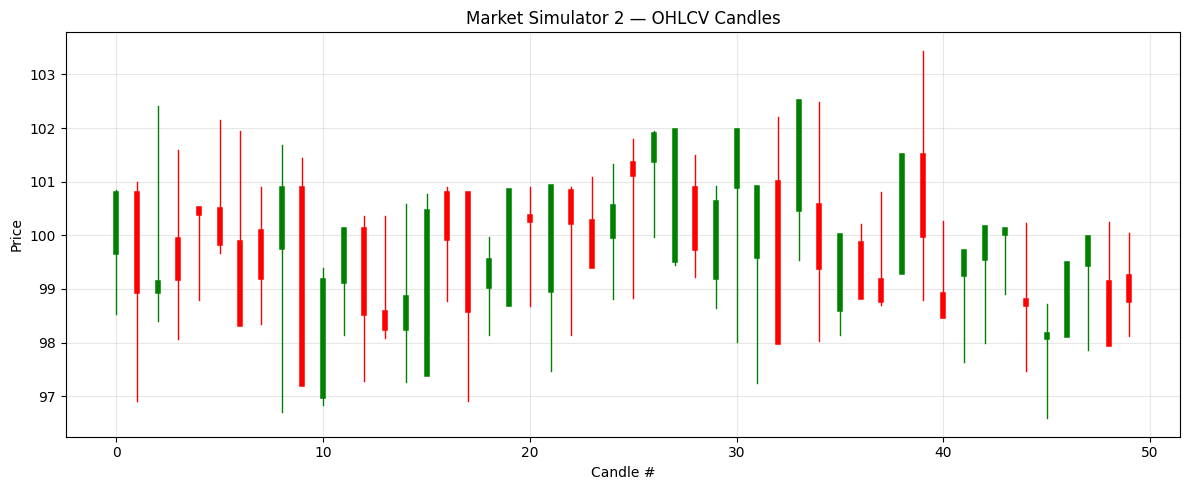

In [16]:
import matplotlib.pyplot as plt

def plot_candles(df, title="Candlestick Plot"):
    if df is None or df.empty:
        print("No OHLCV data to plot.")
        return

    x = np.arange(len(df))
    o = df["open"].values
    h = df["high"].values
    l = df["low"].values
    c = df["close"].values

    fig, ax = plt.subplots(figsize=(12, 5))

    for i in range(len(df)):
        color = "green" if c[i] >= o[i] else "red"
        ax.plot([x[i], x[i]], [l[i], h[i]], color=color, linewidth=1)
        ax.plot([x[i], x[i]], [o[i], c[i]], color=color, linewidth=4)

    ax.set_title(title)
    ax.set_xlabel("Candle #")
    ax.set_ylabel("Price")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Example: plot first 50 candles
plot_candles(df_ohlcv.head(50), title="Market Simulator 2 — OHLCV Candles")

## Visualising Price Evolution

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def plot_trade_prices(trades=None, prices=None, title="Trade Price Evolution",show_avg=True, show_range=True, line_width=1.8):
    if prices is None:
        prices = [t["price"] for t in (trades or []) if "price" in t]

    if len(prices) == 0:
        plt.figure(figsize=(12, 5))
        plt.title("No trades executed")
        plt.axis("off")
        plt.show()
        return

    prices = np.asarray(prices, dtype=float)
    x = np.arange(len(prices))

    avg = prices.mean()
    pmin, pmax = prices.min(), prices.max()

    # Auto markers: only for short series
    use_markers = len(prices) <= 80

    plt.figure(figsize=(12, 5))
    if use_markers:
        plt.plot(x, prices, marker="o", markersize=4, linewidth=line_width, label="Trade Price")
    else:
        plt.plot(x, prices, linewidth=line_width, label="Trade Price")

    if show_avg:
        plt.axhline(avg, linestyle="--", linewidth=1.5, label=f"Average: ${avg:.2f}")

    if show_range:
        plt.fill_between(x, pmin, pmax, alpha=0.12, label=f"Range: {pmin:.2f}–{pmax:.2f}")

    plt.title(title)
    plt.xlabel("Trade #")
    plt.ylabel("Price")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

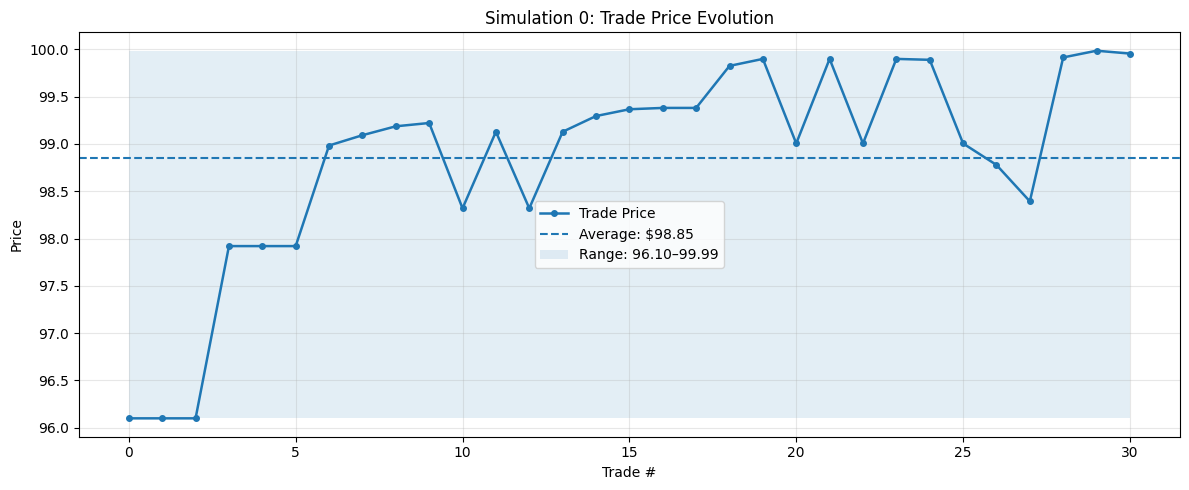

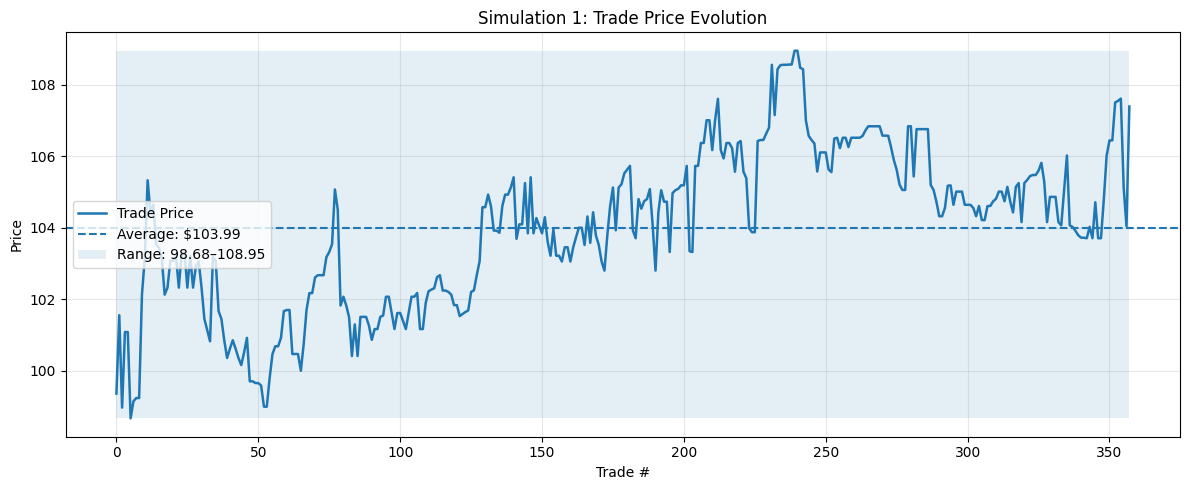

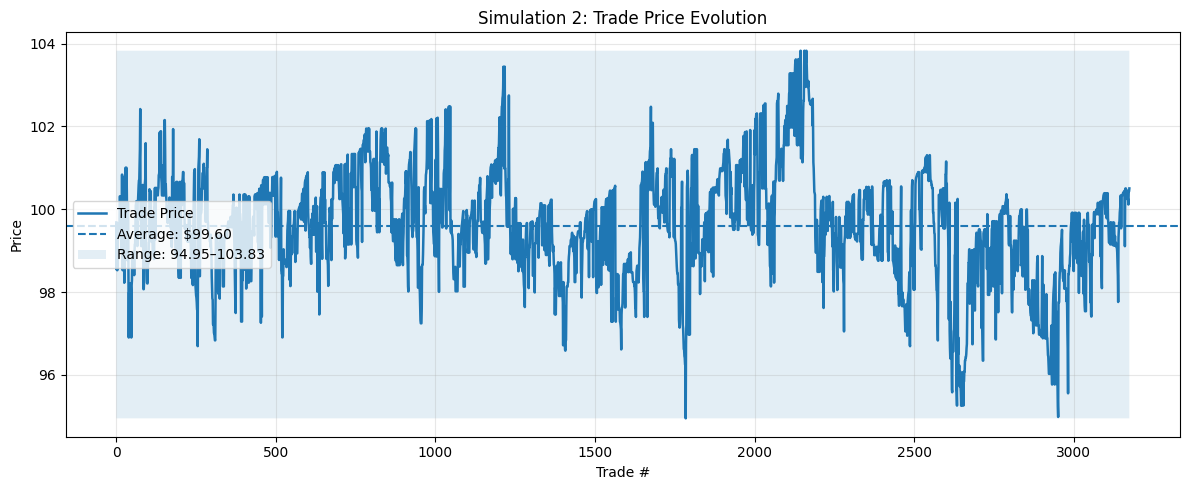

In [18]:
# Plot for MarketSimulator0
plot_trade_prices(trades=trades, title="Simulation 0: Trade Price Evolution")

# Plot for MarketSimulator1
prices1 = sim1.trade_price_series()
plot_trade_prices(prices=prices1, title="Simulation 1: Trade Price Evolution")

# Plot for MarketSimulator2
prices2 = sim2.trade_price_series()
plot_trade_prices(prices=prices2, title="Simulation 2: Trade Price Evolution")